# 03_1. B0 — scorecard (logistic regression on WoE) / B0 — скоринговая карта (логистическая регрессия на WoE)

**EN.** B0 is the banking benchmark of the comparison table: the classic credit scorecard, fitted for the only task of stage 3, Y1 (early default of a loan that is current at t and has never been in default). Every feature of the selected set (18) is replaced by its **WoE** (weight of evidence) from the stage-2 bins: WoE of a bin = ln(share of non-events in the bin / share of events in the bin), so WoE > 0 means "safer than average". A **logistic regression** then adds the WoE values with one coefficient per feature: logit PD = b0 + Σ b_k · WoE_k. Because WoE already orders the risk, every coefficient should be **negative**; a positive one would mean the feature's effect turns around once the others are in the model.

Steps: (1) data — full train with r = 0.2, row weight ω × 1/r (exposure weight × inverse sampling rate); validation after the disaster rule, halves A / B (notebook 03_0); (2) the only tuned hyperparameter is the regularisation strength C, chosen by **log-loss** on half A; (3) coefficients, signs and scorecard points; (4) calibration on half B and quality on half A.

**Log-loss** = −mean[y ln PD + (1 − y) ln(1 − PD)]: the average penalty for the predicted probability of what happened; lower is better, and it rewards both ranking and correct levels. Here it is weighted by ω, as in training.

**RU.** B0 — банковский эталон в таблице сравнения: классическая скоринговая карта для единственной задачи этапа 3 — Y1 (ранний дефолт кредита, который на дату t платит вовремя и ни разу не был в дефолте). Каждый признак отобранного набора (18) заменяется своим **WoE** (weight of evidence) по корзинам этапа 2: WoE корзины = ln(доля «хороших» в корзине / доля «плохих» в корзине), то есть WoE > 0 означает «безопаснее среднего». Затем **логистическая регрессия** складывает значения WoE с одним коэффициентом на признак: logit PD = b0 + Σ b_k · WoE_k. WoE уже упорядочивает риск, поэтому все коэффициенты должны быть **отрицательными**; положительный означал бы, что эффект признака разворачивается, когда в модели есть остальные.

Шаги: (1) данные — полный train при r = 0,2, вес строки ω × 1/r (вес по ОД × обратная доля подвыборки); validation после правила бедствий, половины A / B (ноутбук 03_0); (2) подбирается только сила регуляризации C — по **log-loss** на половине A; (3) коэффициенты, знаки и баллы карты; (4) калибровка на половине B и качество на половине A.

**Log-loss** = −среднее[y ln PD + (1 − y) ln(1 − PD)]: средний штраф за предсказанную вероятность того, что произошло; чем меньше, тем лучше; учитывает и ранжирование, и уровень вероятностей. Здесь он взвешен по ω, как при обучении.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import pickle
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import feature_config
from xai_ews.evaluation.metrics import all_metrics, auc, calibration_curve, log_loss, sigmoid
from xai_ews.models import scorecard as sc
from xai_ews.models.calibration import Platt
from xai_ews.models.data import load_eval, load_train
from xai_ews.paths import MODELS_DIR, PREDICTIONS_DIR, MODELING_DIR

SEL = feature_config()["selected"]
FEATURES, CATS = SEL["features"], SEL["categorical"]
TASKS = ("y1",)
for d in (MODELS_DIR, PREDICTIONS_DIR, MODELING_DIR):
    d.mkdir(parents=True, exist_ok=True)

### 1. Regularisation path / Подбор силы регуляризации

**EN.** C is the inverse strength of the L2 penalty (small C = coefficients pulled towards 0). Ten values from 10⁻⁴ to 10²; for each we fit on train and compute the ω-weighted log-loss and the AUC on half A. **AUC** (area under the ROC curve) = the probability that a random loan with an event gets a higher score than a random loan without one; 0.5 = random, 1 = perfect.

**RU.** C — обратная сила L2-штрафа (малое C — коэффициенты прижимаются к 0). Десять значений от 10⁻⁴ до 10²; для каждого обучаем на train и считаем взвешенный по ω log-loss и AUC на половине A. **AUC** (площадь под ROC-кривой) — вероятность того, что случайный кредит с событием получит более высокий скор, чем случайный кредит без события; 0,5 — случайно, 1 — идеально.

In [2]:
models, paths, data = {}, [], {}
for task in TASKS:
    tr = load_train(task, FEATURES, CATS)
    x, y, w = sc.woe_matrix(tr, FEATURES, task), tr[task].to_numpy(), tr["weight"].to_numpy()
    del tr; gc.collect()
    va = load_eval("validation", task, FEATURES, CATS)
    xv = sc.woe_matrix(va, FEATURES, task)
    data[task] = va.select("loan_identifier", "m", task, "half", "omega", "upb", "mtm_ltv", "property_state").with_columns(
        pl.lit(0.0).alias("logit"))
    a = (va["half"] == "A").to_numpy()
    ya, wa = va[task].to_numpy()[a], va["omega"].to_numpy()[a]
    best = None
    for c in sc.C_GRID:
        m = sc.fit(x, y, w, c)
        z = sc.logit(m, xv[a])
        ll = log_loss(ya, sigmoid(z), wa)
        paths.append({"task": task, "C": c, "log_loss_A": ll, "auc_A": auc(ya, z)})
        if best is None or ll < best[0]:
            best = (ll, c, m)
    models[task] = best[2]
    data[task] = data[task].with_columns(pl.Series("logit", sc.logit(best[2], xv)))
    del x, xv, va; gc.collect()
paths = pd.DataFrame(paths)
paths.to_csv(MODELING_DIR / "b0_regularisation_path.csv", index=False)
paths.pivot(index="C", columns="task", values=["log_loss_A", "auc_A"])

,log_loss_A,auc_A
task,y1,y1
C,,
0.0001,0.0135,0.8417
0.0005,0.0128,0.8437
0.0022,0.0126,0.8483
0.0100,0.0125,0.8514
0.0464,0.0125,0.8518
0.2154,0.0125,0.8513
1.0000,0.0125,0.8511
4.6416,0.0125,0.8510


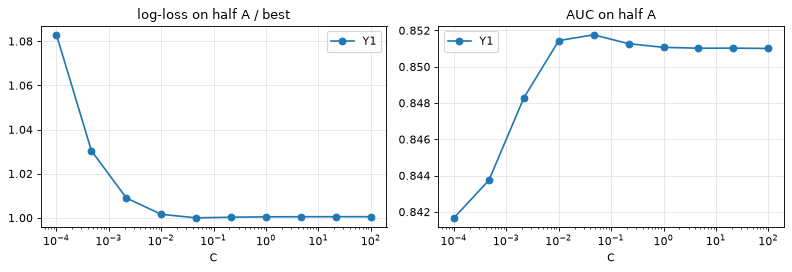

{'y1': 0.046415888336127774}


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for task in TASKS:
    p = paths[paths["task"] == task]
    axes[0].semilogx(p["C"], p["log_loss_A"] / p["log_loss_A"].min(), "o-", label=task.upper())
    axes[1].semilogx(p["C"], p["auc_A"], "o-", label=task.upper())
axes[0].set_title("log-loss on half A / best"); axes[1].set_title("AUC on half A")
for ax in axes:
    ax.set_xlabel("C"); ax.legend()
plt.tight_layout(); plt.show()
print({t: float(m.C) for t, m in models.items()})

**EN. How to read.** Below C ≈ 0.002 the penalty is too strong and both log-loss and AUC get worse (at C = 10⁻⁴ the AUC on half A is 0.842); from C = 0.01 on the curve is flat: log-loss 0.01245–0.01247 and AUC 0.851–0.852 for every C ≥ 0.01 (2.3 M rows leave little room for overfitting 18 coefficients). The best log-loss on half A is at **C ≈ 0.046**; AUC on half A 0.852. Any C ≥ 0.01 would give practically the same model.

**RU. Как читать.** При C меньше ≈ 0,002 штраф слишком сильный, и log-loss, и AUC хуже (при C = 10⁻⁴ AUC на половине A 0,842); начиная с C = 0,01 кривая плоская: log-loss 0,01245–0,01247 и AUC 0,851–0,852 при любом C ≥ 0,01 (при 2,3 млн строк 18 коэффициентам почти негде переобучиться). Лучший log-loss на половине A — при **C ≈ 0,046**; AUC на половине A 0,852. Любое C ≥ 0,01 дало бы практически ту же модель.

### 2. Coefficients and signs / Коэффициенты и знаки

**EN.** One row per feature: the coefficient on WoE (expected < 0) and the **IV** (information value, how strongly the feature separates events from non-events on its own, from stage 2). `sign_ok_y1` marks the expected negative sign.

**RU.** По строке на признак: коэффициент при WoE (ожидается < 0) и **IV** (information value — насколько сильно признак сам по себе разделяет события и не-события, из этапа 2). `sign_ok_y1` отмечает ожидаемый отрицательный знак.

In [4]:
coefs = []
for task in TASKS:
    c = sc.coefficients(models[task], FEATURES)
    b = sc.binners(task)
    c["iv"] = [b[f].iv for f in c["feature"]]
    coefs.append(c.assign(task=task))
coefs = pd.concat(coefs, ignore_index=True)
coefs.to_csv(MODELING_DIR / "b0_coefficients.csv", index=False)
coef_wide = coefs.pivot(index="feature", columns="task", values=["coef", "iv"])
coef_wide["sign_ok_y1"] = coef_wide[("coef", "y1")] < 0
coef_wide.sort_values(("coef", "y1"))

,coef,iv,sign_ok_y1
task,y1,y1,
feature,,,
occupancy_status,-0.7600,0.0263,True
n_curtail_6m,-0.7117,0.2128,True
borrower_credit_score_at_origination,-0.6382,1.1799,True
original_upb,-0.5391,0.1019,True
co_borrower_credit_score_at_origination,-0.5285,0.9260,True
debt_to_income_dti,-0.4588,0.3156,True
property_type,-0.4561,0.0235,True
hpi_chg_since_orig_rel_us,-0.4354,0.0891,True


**EN. How to read.** 16 of the 18 coefficients are negative, as expected. The largest are occupancy (−0.76), the number of curtailment months (−0.71), the borrower and co-borrower credit scores (−0.64 and −0.53), the loan amount (−0.54), DTI and property type (−0.46 each). A coefficient multiplies WoE, so how far a feature can move the score depends also on the spread of its WoE: in points (next table) the credit scores lead. Two coefficients are **positive**:
- **`age`** (+0.82, IV 0.03). On its own an older loan looks slightly safer (02_3). But the payment pace, the curtailments, the current LTV and the house-price change are in the model, and all of them change as the loan ages; given them, the remaining effect of age turns around: loans of 22–34 months get 32–35 points, loans up to 14 months 41–45 points, so the middle-aged loans are the riskier ones. This agrees with the hump shape of the default hazard in loan age and with the expected `+` sign. The effect is moderate (12.8 points).
- **`first_time_home_buyer_indicator`** (+0.16, IV 0.05). On its own first-time buyers are riskier (0.20 % vs 0.11 % on train); in the model they get 2.8 points *more* than other buyers. Their higher risk is probably already carried by correlated features (credit score, DTI, mortgage insurance), and what is left is weak and slightly reversed. In stage 2 this feature was already the weakest one (candidate for removal).

Both stay: the feature set is fixed in stage 2, and the scorecard shows the effects as they are.

**RU. Как читать.** 16 из 18 коэффициентов отрицательные, как и ожидалось. Самые большие — у типа проживания (−0,76), числа месяцев с частичным досрочным погашением (−0,71), FICO заёмщика и созаёмщика (−0,64 и −0,53), суммы кредита (−0,54), DTI и типа жилья (по −0,46). Коэффициент умножается на WoE, поэтому насколько признак может сдвинуть скор, зависит и от разброса его WoE: в баллах (следующая таблица) впереди кредитные рейтинги. Два коэффициента **положительные**:
- **`age`** (+0,82, IV 0,03). Сам по себе более старый кредит выглядит немного безопаснее (02_3). Но в модели есть темп погашения, частичные досрочные погашения, текущий LTV и изменение цен на жильё, а все они меняются с возрастом кредита; при них оставшийся эффект возраста разворачивается: кредиты 22–34 месяцев получают 32–35 баллов, кредиты до 14 месяцев — 41–45 баллов, то есть рискованнее кредиты «среднего» возраста. Это согласуется с «горбатой» формой риска дефолта по возрасту кредита и с ожидаемым знаком `+`. Эффект умеренный (12,8 балла).
- **`first_time_home_buyer_indicator`** (+0,16, IV 0,05). Сами по себе покупатели первого жилья рискованнее (0,20 % против 0,11 % на train); в модели они получают на 2,8 балла *больше* остальных. Их повышенный риск, вероятно, уже учтён коррелированными признаками (рейтинг, DTI, ипотечное страхование), а остаток слабый и чуть развёрнут. На этапе 2 этот признак уже был самым слабым (кандидат на удаление).

Оба остаются: набор признаков зафиксирован на этапе 2, а скоринговая карта показывает эффекты такими, какие они есть.

### 3. Scorecard points / Баллы скоринговой карты

**EN.** The usual banking form of the same model: score = 600 at good:bad odds 50:1, +20 points every time the odds double (PDO = 20). Each bin of each feature gets points; a loan's score is the sum over its bins. Shown: the range of points per feature (max − min), i.e. how much the feature can move the score. The full table is saved to `reports/modeling/b0_points_y1.csv`.

**RU.** Привычная для банка форма той же модели: 600 баллов при соотношении «хорошие : плохие» 50 : 1, +20 баллов при каждом удвоении этого соотношения (PDO = 20). Каждая корзина каждого признака получает баллы; скор кредита — сумма по его корзинам. Ниже — размах баллов по признаку (максимум − минимум), то есть насколько признак может сдвинуть скор. Полная таблица — в `reports/modeling/b0_points_y1.csv`.

In [5]:
spans = {}
for task in TASKS:
    pt = sc.points_table(models[task], FEATURES, task)
    pt.to_csv(MODELING_DIR / f"b0_points_{task}.csv", index=False)
    spans[task] = pt.groupby("feature")["points"].agg(lambda s: s.max() - s.min())
pd.DataFrame(spans).sort_values("y1", ascending=False).round(1)

,y1
feature,
borrower_credit_score_at_origination,62.8000
co_borrower_credit_score_at_origination,58.1000
n_curtail_6m,45.1000
debt_to_income_dti,27.5000
original_interest_rate,25.2000
original_upb,23.8000
property_type,18.7000
mtm_ltv,14.2000
hpi_chg_since_orig_rel_us,13.7000


### 4. Calibration on half B, quality on half A / Калибровка на половине B, качество на половине A

**EN.** Training weights (ω × 1/r) shift the predicted levels, so PD is re-calibrated by **Platt scaling** on half B: PD = sigmoid(a + b · logit), fitted by an unweighted logistic regression. The quality is then measured on half A, which the calibrator has not seen. Metrics (methodology 7): AUC and Gini = 2·AUC − 1; **KS** = the largest gap between the score distributions of events and non-events; **PR-AUC** = area under the precision–recall curve (informative when events are rare); **Brier** = mean squared error of PD; **ECE** = average |mean PD − event rate| over 10 equal-size PD bins (and ECE divided by the event rate); **calibration slope / intercept** = coefficients of a logistic regression of the outcome on logit PD (1 and 0 = perfect; slope < 1 = PD too extreme). These are validation numbers; the final comparison is on test (notebook 03_6).

**RU.** Веса обучения (ω × 1/r) сдвигают уровень прогнозов, поэтому PD перекалибруется **методом Платта** на половине B: PD = sigmoid(a + b · logit), без весов. Качество затем измеряется на половине A, которую калибратор не видел. Метрики (методология, п. 7): AUC и Gini = 2·AUC − 1; **KS** — наибольший разрыв между распределениями скора у событий и не-событий; **PR-AUC** — площадь под кривой precision–recall (информативна при редких событиях); **Brier** — средняя квадратичная ошибка PD; **ECE** — средняя |средняя PD − доля событий| по 10 равным по размеру корзинам PD (и ECE, делённый на долю событий); **calibration slope / intercept** — коэффициенты логистической регрессии исхода на logit PD (1 и 0 — идеально; slope < 1 — PD слишком «крайние»). Это цифры validation; итоговое сравнение — на test (ноутбук 03_6).

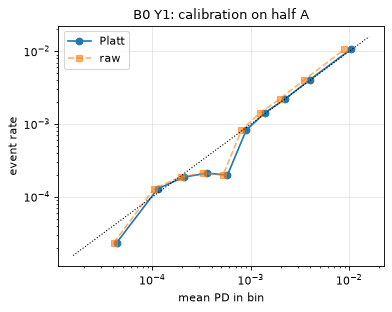

n  events  event_rate  mean_pd    auc   gini     ks  pr_auc  brier  log_loss    ece  ece_norm  cal_slope  cal_intercept
task pd                                                                                                                                 
y1   raw    853029    1695      0.0020   0.0018 0.8518 0.7035 0.5536  0.0117 0.0020    0.0125 0.0003    0.1616     1.0502         0.1235
     platt  853029    1695      0.0020   0.0020 0.8518 0.7035 0.5536  0.0117 0.0020    0.0125 0.0001    0.0567     1.0360        -0.0095

In [6]:
rows, cal = [], {}
fig, axes = plt.subplots(1, len(TASKS), figsize=(5 * len(TASKS), 4), squeeze=False)
for ax, task in zip(axes[0], TASKS):
    d = data[task]
    b, a = d.filter(pl.col("half") == "B"), d.filter(pl.col("half") == "A")
    cal[task] = Platt().fit(b["logit"].to_numpy(), b[task].to_numpy())
    pd_a = cal[task].predict(a["logit"].to_numpy())
    raw_a = sigmoid(a["logit"].to_numpy())
    rows.append({"task": task, "pd": "raw", **all_metrics(a[task].to_numpy(), raw_a)})
    rows.append({"task": task, "pd": "platt", **all_metrics(a[task].to_numpy(), pd_a),
                 "platt_a": cal[task].a, "platt_b": cal[task].b})
    mp, er = calibration_curve(a[task].to_numpy(), pd_a, bins=10)
    ax.loglog(mp, er, "o-", label="Platt"); mp, er = calibration_curve(a[task].to_numpy(), raw_a, bins=10)
    ax.loglog(mp, er, "s--", alpha=0.6, label="raw")
    lim = [min(mp.min(), er[er > 0].min()) / 1.5, max(mp.max(), er.max()) * 1.5]
    ax.plot(lim, lim, "k:", lw=1); ax.set_title(f"B0 {task.upper()}: calibration on half A")
    ax.set_xlabel("mean PD in bin"); ax.set_ylabel("event rate"); ax.legend()
    data[task] = d.with_columns(pl.Series("pd", cal[task].predict(d["logit"].to_numpy())))
plt.tight_layout(); plt.show()
b0_val = pd.DataFrame(rows)
b0_val.to_csv(MODELING_DIR / "b0_validation_metrics.csv", index=False)
b0_val.set_index(["task", "pd"])[["n", "events", "event_rate", "mean_pd", "auc", "gini", "ks", "pr_auc", "brier",
                                  "log_loss", "ece", "ece_norm", "cal_slope", "cal_intercept"]]

**EN. How to read.** The raw PD of the weighted model is a little too low: mean PD 0.176 % against an event rate of 0.199 % on half A; calibration intercept +0.12 in logits, i.e. the true level is about 13 % higher. The slope is already close to 1 (1.05). Platt on half B (a = 0.21, b = 1.01) therefore mainly shifts the level: on half A the mean PD becomes 0.201 %, slope 1.04, intercept −0.01, ECE 0.0001 (6 % of the event rate; raw 16 %) — well calibrated. Platt does not change the order of the loans, so AUC, KS and PR-AUC are the same before and after it. Discrimination: **AUC 0.852 (Gini 0.70), KS 0.55, PR-AUC 0.012** against 0.0020 for a random order. B0 is a strong benchmark: the tuned CatBoost M1 reaches 0.863 on the same half A (03_2), so the gain of the boosted trees over the scorecard is about 0.011 AUC.

**RU. Как читать.** Сырая PD модели с весами немного занижена: средняя PD 0,176 % при доле событий 0,199 % на половине A; calibration intercept +0,12 в логитах, то есть реальный уровень примерно на 13 % выше. Наклон уже близок к 1 (1,05). Поэтому калибровка Платта на половине B (a = 0,21, b = 1,01) в основном сдвигает уровень: на половине A средняя PD становится 0,201 %, slope 1,04, intercept −0,01, ECE 0,0001 (6 % доли событий; до калибровки 16 %) — модель хорошо откалибрована. Калибровка Платта не меняет порядок кредитов, поэтому AUC, KS и PR-AUC до и после неё одинаковы. Дискриминация: **AUC 0,852 (Gini 0,70), KS 0,55, PR-AUC 0,012** против 0,0020 у случайного порядка. B0 — сильный эталон: подобранный CatBoost M1 на той же половине A даёт 0,863 (03_2), то есть бустинг выигрывает у скоринговой карты около 0,011 AUC.

In [7]:
for task in TASKS:
    (MODELS_DIR / f"b0_{task}.pkl").write_bytes(pickle.dumps({"model": models[task], "platt": cal[task],
                                                              "features": FEATURES}))
    data[task].select("loan_identifier", "m", "half", "logit", "pd").write_parquet(
        PREDICTIONS_DIR / f"b0_{task}_validation.parquet")
print(sorted(p.name for p in MODELS_DIR.glob("b0_*")))

['b0_y1.pkl']


**EN. Summary.** B0 for Y1 is fitted, calibrated and saved (`data/processed/models/b0_y1.pkl`, validation predictions in `data/processed/predictions/b0_y1_validation.parquet`). 18 WoE features, C ≈ 0.046 (any C ≥ 0.01 gives practically the same model). Validation half A: AUC 0.852, KS 0.55, PR-AUC 0.012; after Platt the calibration slope is 1.04 and the intercept −0.01. 16 of 18 signs agree with the expected direction; the two positive coefficients (loan age, first-time buyer) are effects conditional on the correlated features (12.8 and 2.8 points). The test numbers come only in 03_6.

**RU. Итог.** B0 для Y1 обучена, откалибрована и сохранена (`data/processed/models/b0_y1.pkl`, прогнозы validation — в `data/processed/predictions/b0_y1_validation.parquet`). 18 признаков WoE, C ≈ 0,046 (любое C ≥ 0,01 даёт практически ту же модель). Половина A validation: AUC 0,852, KS 0,55, PR-AUC 0,012; после Платта calibration slope 1,04, intercept −0,01. 16 из 18 знаков совпадают с ожидаемыми; два положительных коэффициента (возраст кредита, первая покупка жилья) — эффекты при учёте коррелированных признаков (12,8 и 2,8 балла). Цифры test — только в 03_6.